# Монокулярная ORB VO (без замыкания петель)

In [1]:
from pathlib import Path
import csv
import json
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'scripts' else Path.cwd()
print('Project root:', ROOT)

IMAGE_DIR = ROOT / 'images'
TIMES_PATH = ROOT / 'calib' / 'times.txt'
CALIB_PATH = ROOT / 'calib' / 'camera.yaml'

RESULTS_DIR = ROOT / 'results' / 'VO' / 'ORB'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MONO_SCALE_CONSTANT = 1.0

plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['font.size'] = 18

Project root: /home/sadovetsrv/dev_KAMAZ/big_dataset


### Предобработка

После устранения дисторсии создаём постоянную маску: нулевые области соответствуют перилам и другим элементам конструкции. Маска покрывает трубы с небольшим запасом, но сохраняет дорогу и борта карьера.

In [2]:
image_paths = sorted(IMAGE_DIR.glob('*.png'))
timestamps = np.loadtxt(TIMES_PATH)

print(f'Frames: {len(image_paths)}')
print(f'Duration: {timestamps[-1] - timestamps[0]:.3f} s')

Frames: 599
Duration: 59.899 s


In [3]:
# FileStorage открывает YAML калибровки в режиме чтения.
storage = cv2.FileStorage(str(CALIB_PATH), cv2.FILE_STORAGE_READ)

# getNode(...).real() читает скалярные параметры модели.
fx = storage.getNode('Camera.fx').real()
fy = storage.getNode('Camera.fy').real()
cx = storage.getNode('Camera.cx').real()
cy = storage.getNode('Camera.cy').real()

# Аналогично читаем пять коэффициентов дисторсии и закрываем YAML-файл.
distortion = np.array([storage.getNode(name).real() for name in
                       ['Camera.k1', 'Camera.k2', 'Camera.p1', 'Camera.p2', 'Camera.k3']])
storage.release()

if min(fx, fy) <= 0:
    raise ValueError('Заполните fx, fy, cx, cy и дисторсию в calib/camera_orb.yaml')

K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=np.float64)

# imread загружает первый кадр в grayscale.
sample = cv2.imread(str(image_paths[0]), cv2.IMREAD_GRAYSCALE)
height, width = sample.shape

# initUndistortRectifyMap заранее вычисляет координаты источника для каждого выходного пикселя.
map_x, map_y = cv2.initUndistortRectifyMap(K, distortion, None, K, (width, height), cv2.CV_32FC1)

def load_gray(index):
    # Загружаем кадр по индексу в grayscale.
    gray = cv2.imread(str(image_paths[index]), cv2.IMREAD_GRAYSCALE)
    
    if gray is None:
        raise RuntimeError(f'Cannot read {image_paths[index]}')
    
    # remap применяет карты устранения дисторсии с билинейной интерполяцией яркости.
    return cv2.remap(gray, map_x, map_y, cv2.INTER_LINEAR)

print('K =\n', K)
print('Distortion =', distortion)

K =
 [[525.   0. 640.]
 [  0. 315. 360.]
 [  0.   0.   1.]]
Distortion = [0. 0. 0. 0. 0.]


Исключено маской: 215738 из 921600 пикселей (23.41%)
Осталось для ORB: 76.59% кадра


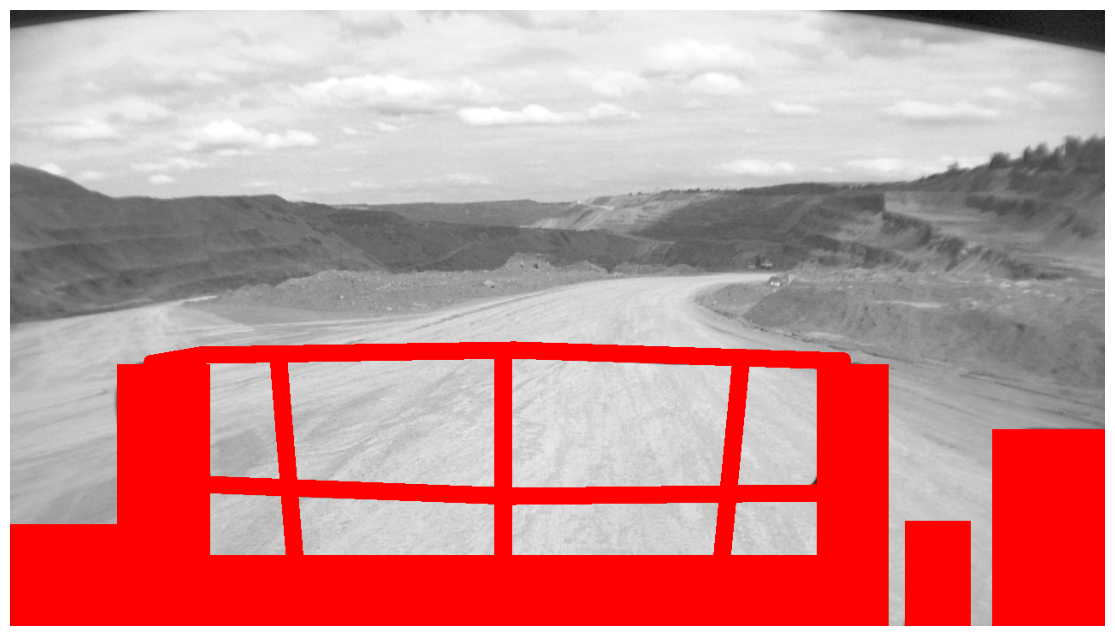

In [4]:
# Белый (255) — область поиска ORB, чёрный (0) — исключённая область.
feature_mask = np.full((height, width), 255, dtype=np.uint8)

# ЛИНИИ
# Точка (x, y) задаётся долями ширины и высоты: 
# (0, 0) — левый верхний угол, (1, 1) — правый нижний.
RAIL_POLYLINES = [
    # Верхняя горизонтальная труба и её изгибы.
    [(0.130, 0.575), (0.175, 0.560), (0.460, 0.552),
     (0.670, 0.564), (0.760, 0.570)],
    
    # Далее каждый список описывает отдельную стойку или фрагмент перил.
    [(0.245, 0.560), (0.260, 0.900)],
    [(0.450, 0.560), (0.450, 0.900)],
    [(0.668, 0.570), (0.650, 0.900)],
    
    [(0.175, 0.770), (0.460, 0.790), (0.735, 0.785)],
]

# ПРЯМОУГОЛЬНИКИ. Формат: (x_лево, y_верх, x_право, y_низ).
# Вся внутренняя область закрашивается нулём и исключается из детекции.
STATIC_RECTANGLES = [
    (0.000, 0.840, 0.100, 1.000),  # Перила в левой нижней части кадра.
    (0.100, 0.580, 0.180, 1.000),  # Перила слева "вверх".
    (0.120, 0.890, 0.800, 1.000),  # Нижняя площадка.
    (0.740, 0.580, 0.800, 1.000),  # Перила справа "вверх".
    (0.820, 0.835, 0.875, 1.000),  # Перила справа "между".
    (0.900, 0.685, 1.000, 1.000),  # Перила в правой нижней части кадра.
]

# Толщина линий и дополнительный запас вокруг ВСЕХ исключённых фигур, в пикселях.
# Если ORB всё ещё находит точки рядом с перилами, сначала увеличь MASK_MARGIN_PX.
RAIL_THICKNESS_PX = max(5, round(min(height, width) * 0.02))
MASK_MARGIN_PX = 3

def normalized_to_pixel(point):
    x, y = point
    return round(x * (width - 1)), round(y * (height - 1))

for polyline in RAIL_POLYLINES:
    points = np.array([normalized_to_pixel(point) for point in polyline], dtype=np.int32)
    
    # OpenCV рисует ломаную чёрным цветом (0), то есть помечает её как запрещённую.
    cv2.polylines(feature_mask, [points], False, 0, RAIL_THICKNESS_PX, cv2.LINE_AA)

for x1, y1, x2, y2 in STATIC_RECTANGLES:
    # thickness=-1 в cv2.rectangle означает закрашенный прямоугольник, а не только рамку.
    cv2.rectangle(feature_mask, normalized_to_pixel((x1, y1)),
                  normalized_to_pixel((x2, y2)), 0, thickness=-1)

# Расширяем чёрные области на MASK_MARGIN_PX во все стороны.
excluded_mask = 255 - feature_mask
if MASK_MARGIN_PX > 0:
    kernel_size = 2 * MASK_MARGIN_PX + 1
    
    # Морфологическая дилатация OpenCV расширяет ненулевые области excluded_mask.
    excluded_mask = cv2.dilate(excluded_mask, np.ones((kernel_size, kernel_size), np.uint8))
    
feature_mask = 255 - excluded_mask

# Считаем площадь именно итоговой маски: после объединения фигур и дилатации.
excluded_pixels = np.count_nonzero(feature_mask == 0)
excluded_percent = 100.0 * excluded_pixels / feature_mask.size
print(f'Исключено маской: {excluded_pixels} из {feature_mask.size} пикселей ({excluded_percent:.2f}%)')
print(f'Осталось для ORB: {100.0 - excluded_percent:.2f}% кадра')

# cvtColor преобразует grayscale в RGB, чтобы красным показать исключённые области.
mask_preview = cv2.cvtColor(load_gray(0), cv2.COLOR_GRAY2RGB)
mask_preview[feature_mask == 0] = (255, 0, 0)

figure = plt.figure()
plt.imshow(mask_preview)
plt.axis('off')
figure.savefig(RESULTS_DIR / 'orb_preprocessing_mask.png', dpi=200, bbox_inches='tight')

## 1. Feature Detection

ORB состоит из двух частей: **детектор** находит устойчивые ключевые точки, а **дескриптор** описывает изображение вокруг каждой точки. Детектор работает на пирамиде масштабов, поэтому одна и та же структура может находиться при разном размере в кадре.

- центр круга — координата ключевой точки;
- радиус круга — размер её характерной окрестности (`KeyPoint.size`), связанный с масштабом пирамиды; 
- радиус с радиальной линией — масштаб и главная ориентация точки; линия показывает направление, вычисленное по распределению яркости в окрестности.

Для каждой точки ORB вычисляет 256-битный бинарный дескриптор.

Detected keypoints: 1932
Descriptor matrix: (1932, 32) uint8


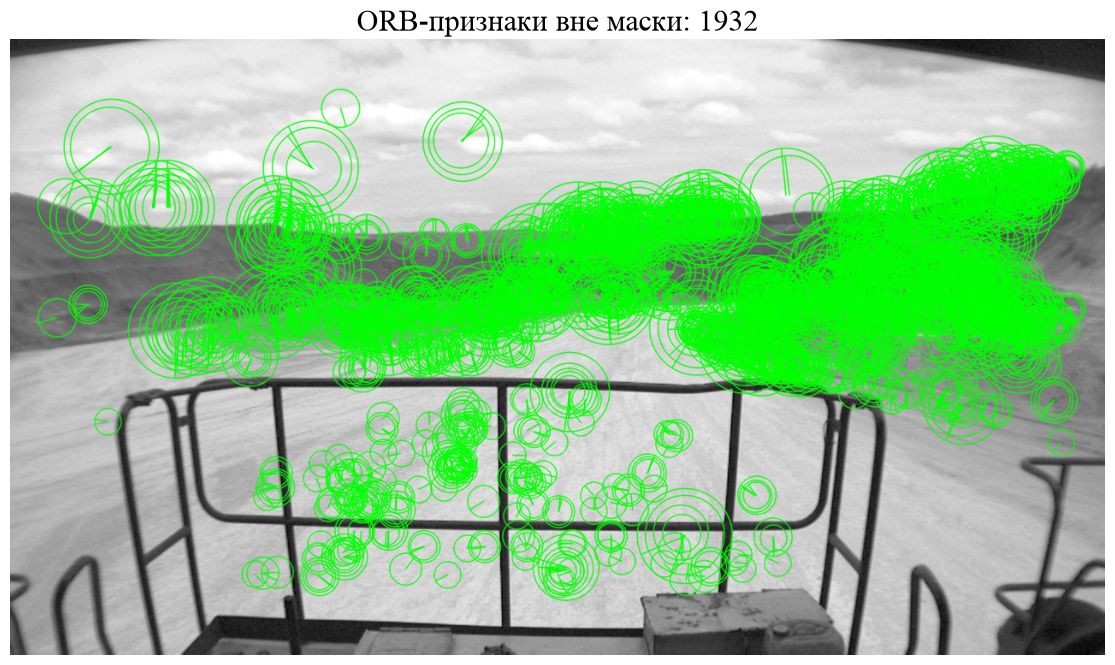

In [5]:
# Пирамида используется полностью: грубые уровни лучше помогают захвату движения,
# а точность окончательной PnP-позы позже повышается по точкам мелких уровней.
orb = cv2.ORB_create(nfeatures=3000, scaleFactor=1.2, nlevels=8, fastThreshold=15)

gray0 = load_gray(0)

# detectAndCompute возвращает ключевые точки и матрицу N×32 типа uint8:
# одна строка = один 256-битный дескриптор. feature_mask запрещает поиск в нулевых зонах.
keypoints0, descriptors0 = orb.detectAndCompute(gray0, feature_mask)
print('Detected keypoints:', len(keypoints0))
print('Descriptor matrix:', descriptors0.shape, descriptors0.dtype)

# drawKeypoints с DRAW_RICH_KEYPOINTS рисует масштаб кругом и ориентацию линией.
feature_image = cv2.drawKeypoints(gray0, keypoints0, None, color=(0, 255, 0),
                                  flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

figure = plt.figure()
plt.imshow(feature_image)
plt.title(f'ORB-признаки вне маски: {len(keypoints0)}')
plt.axis('off')
figure.savefig(RESULTS_DIR / 'orb_feature_detection.png', dpi=200, bbox_inches='tight')

# Обёртка используется в последовательном трекинге; point_ids связывает 2D-точки с картой.
def detect_frame(index):
    gray = load_gray(index)
    # detectAndCompute повторно ищет ORB-признаки с той же неизменной маской.
    keypoints, descriptors = orb.detectAndCompute(gray, feature_mask)
    return {'index': index, 'gray': gray, 'keypoints': keypoints,
            'descriptors': descriptors, 'point_ids': np.full(len(keypoints), -1, dtype=np.int64),
            'pose': None}

frame0 = {'index': 0, 'gray': gray0, 'keypoints': keypoints0, 'descriptors': descriptors0,
          'point_ids': np.full(len(keypoints0), -1, dtype=np.int64), 'pose': np.eye(4)}

## 2. Feature Tracking

1. `BFMatcher(NORM_HAMMING)` сравнивает бинарные дескрипторы по числу различающихся битов.
2. `knnMatch(..., k=2)` возвращает двух ближайших кандидатов.
3. Ratio test и взаимная проверка оставляют только однозначные пары A→B и B→A.
4. В `DMatch` поля `queryIdx/trainIdx` связывают индексы точек двух кадров.

Начиная с Map Tracking **полный перебор** заменяется **направленным поиском**: 3D-точка проецируется в прогнозируемую позу, а дескриптор ищется только среди текущих ключевых точек внутри окна. Это ближе к `SearchByProjection` в ORB-SLAM2 и уменьшает как вычисления, так и случайные совпадения с похожей текстурой в другой части кадра.

Keypoints: 1932 → 2101
Mutual ratio-test matches: 477
Matches / frame-0 keypoints: 24.7%


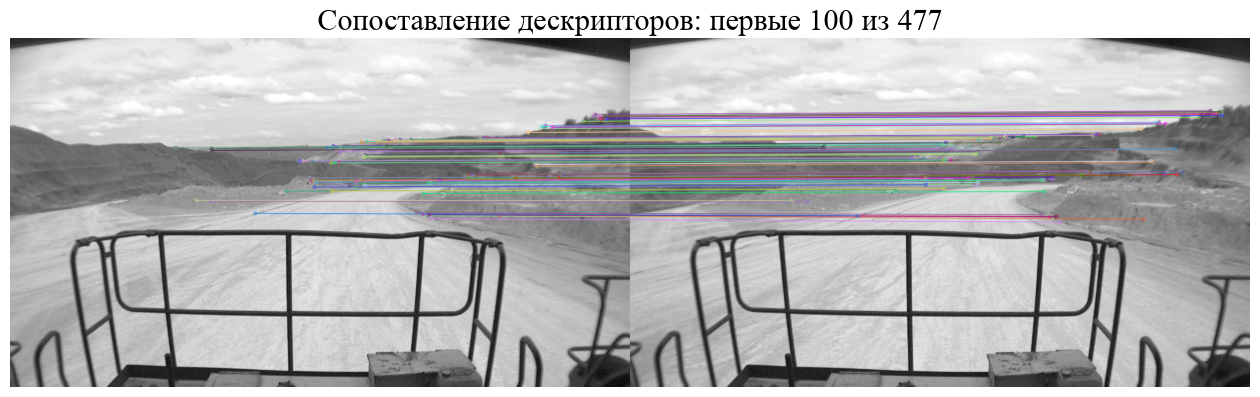

In [6]:
def match_descriptors(query, train, ratio=0.75):
    
    # BFMatcher выполняет полный перебор; NORM_HAMMING выбран для бинарных ORB-дескрипторов.
    matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
    # Для каждого дескриптора knnMatch возвращает два ближайших соседа (k=2).
    forward = matcher.knnMatch(query, train, k=2)
    backward = matcher.knnMatch(train, query, k=2)
    # Ratio test отбрасывает пары, у которых второй кандидат слишком похож на лучший.
    forward_good = [pair[0] for pair in forward if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance]
    backward_good = [pair[0] for pair in backward if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance]
    # Взаимная проверка: индексы должны образовывать пару в обоих направлениях.
    reverse = {match.queryIdx: match.trainIdx for match in backward_good}
    
    return [match for match in forward_good if reverse.get(match.trainIdx) == match.queryIdx]

INIT_FRAME_INDEX = 10
TRACK_FRAME_INDEX = INIT_FRAME_INDEX + 1
gray1 = load_gray(INIT_FRAME_INDEX)

# Повторяем детекцию ORB на новом кадре с той же маской предобработки.
keypoints1, descriptors1 = orb.detectAndCompute(gray1, feature_mask)
matches = match_descriptors(descriptors0, descriptors1)

print(f'Keypoints: {len(keypoints0)} → {len(keypoints1)}')
print(f'Mutual ratio-test matches: {len(matches)}')
print(f'Matches / frame-0 keypoints: {len(matches) / max(len(keypoints0), 1):.1%}')

# drawMatches соединяет сопоставленные точки; одиночные точки скрыты для читаемости.
match_image = cv2.drawMatches(gray0, keypoints0, gray1, keypoints1, matches[:100], None,
                              flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

figure = plt.figure()
plt.imshow(match_image)

plt.title(f'Сопоставление дескрипторов: первые 100 из {len(matches)}')
plt.axis('off')
figure.savefig(RESULTS_DIR / 'orb_feature_tracking.png', dpi=200, bbox_inches='tight')

frame1 = {'index': INIT_FRAME_INDEX, 'gray': gray1, 'keypoints': keypoints1,
          'descriptors': descriptors1, 'point_ids': np.full(len(keypoints1), -1, dtype=np.int64),
          'pose': None}
initialization_matches = matches

## 3. Motion Estimation

Из массива `matches` берём пары пиксельных координат `points0` и `points1`. По ним нужно найти относительное движение камеры, но часть соответствий всё ещё ошибочна.

**Essential matrix и RANSAC:**

1. Матрица `E` связывает лучи двух камер эпиполярным условием: соответствующая точка должна лежать около эпиполярной линии. Калибровка `K` переводит пиксели в нормированные координаты.
2. RANSAC многократно выбирает небольшую случайную группу соответствий, строит по ней кандидата `E` и проверяет остальные пары.
3. Пары с эпиполярной ошибкой не более `threshold=1.0` пикселя получают значение 1 в `essential_mask` — это **inliers**. Остальные — **outliers**. Ниже они показаны зелёным и красным соответственно.
`prob=0.999` задаёт желаемую вероятность найти согласованную модель; это не процент inliers.

**Восстановление позы:** `recoverPose` разлагает `E` на поворот `R` и направление перевода `t`, затем проверяет гипотезы через положительную глубину точек перед обеими камерами. `pose_mask` может содержать меньше точек, чем `essential_mask`, поскольку эпиполярный inlier не обязан иметь физически корректную глубину.

Длина `t` нормирована: монокулярная пара кадров даёт направление перевода, но не метры без внешнего масштаба. 

Essential inliers: 365/477 (76.5%)
Positive-depth pose inliers: 68
Rotation: 1.887 deg
Unit-scale translation direction: [ 0.19473584  0.20765335 -0.95862299]
ВЫВОД: зелёные соответствия согласуются с одной эпиполярной геометрией; красные отброшены RANSAC.


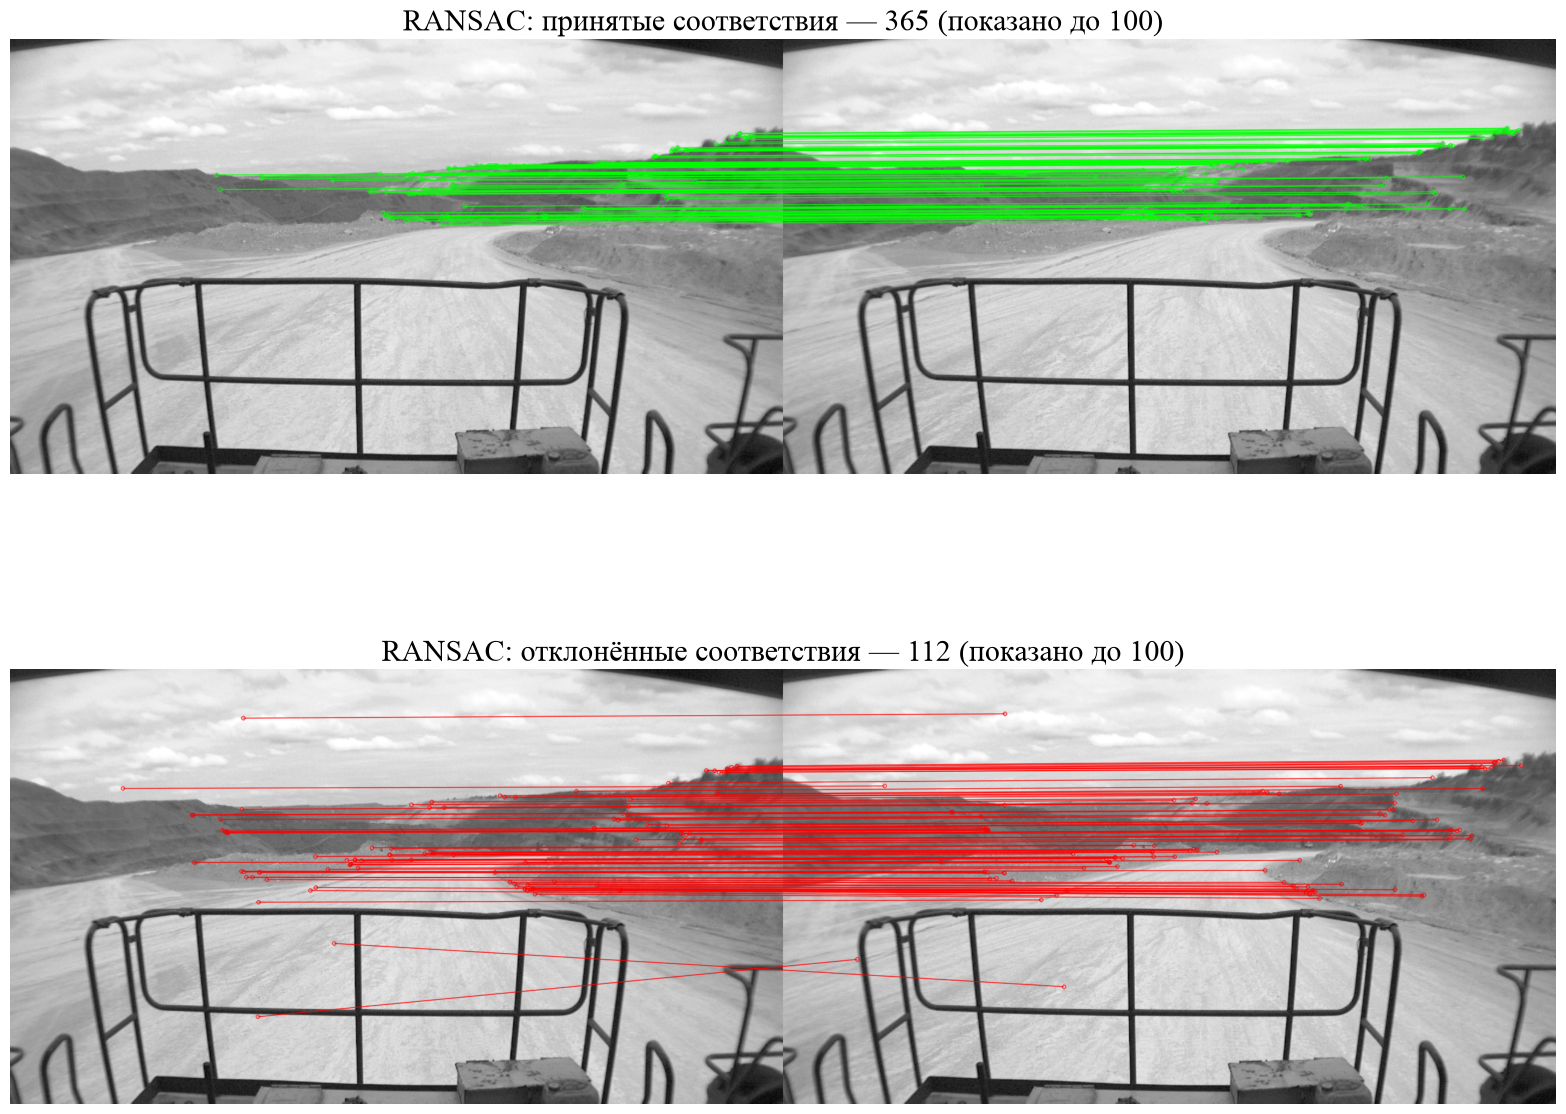

In [ ]:
# Индексы DMatch превращаем в два массива пиксельных координат shape (N, 2).
points0 = np.float32([keypoints0[m.queryIdx].pt for m in matches])
points1 = np.float32([keypoints1[m.trainIdx].pt for m in matches])

# findEssentialMat оценивает E методом RANSAC; threshold — эпиполярный порог в пикселях.
# essential_mask — бинарный вектор: 1 для inliers, 0 для outliers.
E, essential_mask = cv2.findEssentialMat(points0, points1, K, method=cv2.RANSAC,
                                         prob=0.999, threshold=1.0)

if E is None or E.shape != (3, 3):
    raise RuntimeError('Essential matrix estimation failed')

# recoverPose получает R и единичный вектор t из E, проверяя положительную глубину точек.
_, R, t, pose_mask = cv2.recoverPose(E, points0, points1, K, mask=essential_mask.copy())

essential_inliers = int(essential_mask.sum())
pose_inliers = int(pose_mask.sum())

if pose_inliers < 20:
    raise RuntimeError('Мало точек с положительной глубиной: увеличьте INIT_FRAME_INDEX для большего параллакса')

# Мировая система совпадает с камерой кадра 0. Поза кадра 10 — преобразование world→camera.
# Масштаб 1.0 задаёт условную единицу длины всей монокулярной карты, а не метры.
frame0['pose'] = np.eye(4)
frame1['pose'] = np.eye(4)
frame1['pose'][:3, :3] = R
frame1['pose'][:3, 3] = MONO_SCALE_CONSTANT * t.ravel()

# Угол поворота получаем из следа ортогональной матрицы R: trace(R)=1+2cos(theta).
rotation_deg = np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1)))

print(f'Essential inliers: {essential_inliers}/{len(matches)} ({essential_inliers / len(matches):.1%})')
print(f'Positive-depth pose inliers: {pose_inliers}')
print(f'Rotation: {rotation_deg:.3f} deg')
print('Unit-scale translation direction:', t.ravel())

# Разделяем исходные DMatch по маске RANSAC, сохраняя соответствие индексов.
is_ransac_inlier = essential_mask.ravel() > 0
inlier_matches = [match for match, keep in zip(matches, is_ransac_inlier) if keep]
outlier_matches = [match for match, keep in zip(matches, is_ransac_inlier) if not keep]

# drawMatches рисует центры точек и соединяющие линии. Зелёный — принято, красный — отклонено.
ransac_inlier_image = cv2.drawMatches(
    gray0, keypoints0, gray1, keypoints1, inlier_matches[:100], None,
    matchColor=(0, 255, 0), singlePointColor=(0, 255, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

ransac_outlier_image = cv2.drawMatches(
    gray0, keypoints0, gray1, keypoints1, outlier_matches[:100], None,
    matchColor=(255, 0, 0), singlePointColor=(255, 0, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

fig, axes = plt.subplots(2, 1, figsize=(16, 14))

axes[0].imshow(ransac_inlier_image)
axes[0].set_title(f'RANSAC: принятые соответствия — {len(inlier_matches)} (показано до 100)')
axes[0].axis('off')

axes[1].imshow(ransac_outlier_image)
axes[1].set_title(f'RANSAC: отклонённые соответствия — {len(outlier_matches)} (показано до 100)')
axes[1].axis('off')

fig.tight_layout()
fig.savefig(RESULTS_DIR / 'orb_ransac.png', dpi=200, bbox_inches='tight')

## 4. Triangulation

**Вход:** два кадра с известными позами `T_cw` и пары пикселей, которым ещё не назначен `point_id`. Матрица `P = K [R|t]` проецирует мировую 3D-точку в изображение. `cv2.triangulatePoints` находит точку, лучи которой из двух камер наилучшим образом пересекаются.

После деления однородных координат на последнюю компоненту получаем `xyz_world`. Поскольку обе матрицы `P_ref` и `P_cur` уже построены как **world→camera**, результат OpenCV сразу принадлежит общей мировой системе. Дополнительно применять `R_ref.T` к этому результату не нужно: такое повторное преобразование было ошибкой и полностью мешало пополнению карты. Для проверки положительной глубины мировая точка отдельно переводится в `xyz_ref` и `xyz_cur`.

Далее последовательно отбрасываем:

- нечисленные результаты и точки за хотя бы одной камерой (`Z <= 0`);
- среднюю ошибку репроекции более **1,5 px** — 3D-точка плохо возвращается в исходные пиксели;
- параллакс не более **0,35°** — лучи почти параллельны, поэтому небольшая ошибка пикселя создаёт огромную ошибку глубины. Именно этот критерий подавляет большинство очень далёких точек и неба без изменения маски.

**Выход функции:** новые мировые 3D-точки, их дескрипторы, параллакс, ошибка репроекции и связи `point_id` в обоих кадрах. `new_points=0` означает не отсутствие изображения, а отсутствие соответствий, прошедших все геометрические проверки. Диагностика ниже показывает, на каком фильтре теряются кандидаты.

In [8]:
map_points = []
map_descriptors = []
map_parallax_deg = []
map_reprojection_px = []
map_observations = []
map_last_seen = []
MIN_TRIANGULATION_PARALLAX_DEG = 0.35
MAX_TRIANGULATION_REPROJECTION_PX = 1.5

def triangulate_new(reference, current, matches):
    # Триангулируем только новые наблюдения, чтобы не создавать дубликат известной 3D-точки.
    candidates = [m for m in matches
                  if reference['point_ids'][m.queryIdx] < 0 and current['point_ids'][m.trainIdx] < 0]
    empty_result = {'new_points': 0, 'median_reprojection_px': np.nan,
                    'median_parallax_deg': np.nan, 'candidates': len(candidates),
                    'epipolar_pass': 0, 'positive_depth': 0, 'reprojection_pass': 0, 'parallax_pass': 0}
    if len(candidates) < 8:
        return empty_result

    # До триангуляции отбрасываем дескрипторные пары, несовместимые с уже известной относительной позой.
    # Это геометрический фильтр ложных совпадений, а не изменение маски изображения.
    K_inv = np.linalg.inv(K)
    relative = current['pose'] @ np.linalg.inv(reference['pose'])
    R_rel, t_rel = relative[:3, :3], relative[:3, 3]
    t_x = np.array([[0, -t_rel[2], t_rel[1]],
                    [t_rel[2], 0, -t_rel[0]],
                    [-t_rel[1], t_rel[0], 0]], dtype=np.float64)
    E_relative = t_x @ R_rel
    geometric_candidates = []
    for match in candidates:
        ref_hom = np.array([*reference['keypoints'][match.queryIdx].pt, 1.0])
        cur_hom = np.array([*current['keypoints'][match.trainIdx].pt, 1.0])
        ref_normal = K_inv @ ref_hom
        cur_normal = K_inv @ cur_hom
        line_cur = K_inv.T @ (E_relative @ ref_normal)
        line_ref = K_inv.T @ (E_relative.T @ cur_normal)
        error_cur = abs(line_cur @ cur_hom) / max(np.hypot(line_cur[0], line_cur[1]), 1e-12)
        error_ref = abs(line_ref @ ref_hom) / max(np.hypot(line_ref[0], line_ref[1]), 1e-12)
        if 0.5 * (error_cur + error_ref) < 2.0:
            geometric_candidates.append(match)
    epipolar_pass = len(geometric_candidates)
    candidates = geometric_candidates
    if len(candidates) < 8:
        return {**empty_result, 'epipolar_pass': epipolar_pass}

    ref_px = np.float32([reference['keypoints'][m.queryIdx].pt for m in candidates])
    cur_px = np.float32([current['keypoints'][m.trainIdx].pt for m in candidates])
    P_ref = K @ reference['pose'][:3, :]
    P_cur = K @ current['pose'][:3, :]

    # triangulatePoints пересекает лучи и возвращает однородные точки 4×N в системе reference.
    homogeneous = cv2.triangulatePoints(P_ref, P_cur, ref_px.T, cur_px.T)
    # Обе P построены как world→camera, поэтому результат triangulatePoints — сразу XYZ мира.
    xyz_world = (homogeneous[:3] / homogeneous[3]).T
    # Для проверки глубины отдельно переводим мировую точку в каждую камеру.
    xyz_ref = (reference['pose'][:3, :3] @ xyz_world.T + reference['pose'][:3, 3:4]).T
    xyz_cur = (current['pose'][:3, :3] @ xyz_world.T + current['pose'][:3, 3:4]).T
    finite = np.isfinite(xyz_ref).all(axis=1) & np.isfinite(xyz_world).all(axis=1)
    positive = finite & (xyz_ref[:, 2] > 0) & (xyz_cur[:, 2] > 0)
    error = np.full(len(candidates), np.inf)
    parallax = np.zeros(len(candidates))
    C_ref = -reference['pose'][:3, :3].T @ reference['pose'][:3, 3]
    C_cur = -current['pose'][:3, :3].T @ current['pose'][:3, 3]

    for point_index in np.flatnonzero(positive):
        # Обратная проекция измеряет согласованность найденной 3D-точки с обоими пикселями.
        proj_ref = K @ xyz_ref[point_index]
        proj_cur = K @ xyz_cur[point_index]
        uv_ref = proj_ref[:2] / proj_ref[2]
        uv_cur = proj_cur[:2] / proj_cur[2]
        error[point_index] = 0.5 * (np.linalg.norm(uv_ref - ref_px[point_index]) +
                                    np.linalg.norm(uv_cur - cur_px[point_index]))
        ray_ref = xyz_world[point_index] - C_ref
        ray_cur = xyz_world[point_index] - C_cur
        cosine = np.dot(ray_ref, ray_cur) / (np.linalg.norm(ray_ref) * np.linalg.norm(ray_cur))
        parallax[point_index] = np.degrees(np.arccos(np.clip(cosine, -1, 1)))

    reprojection_ok = positive & (error < MAX_TRIANGULATION_REPROJECTION_PX)
    parallax_ok = reprojection_ok & (parallax > MIN_TRIANGULATION_PARALLAX_DEG)
    valid = parallax_ok
    for match, xyz, angle, reproj, keep in zip(candidates, xyz_world, parallax, error, valid):
        if not keep:
            continue
        point_id = len(map_points)
        map_points.append(xyz.copy())
        map_descriptors.append(current['descriptors'][match.trainIdx].copy())
        map_parallax_deg.append(float(angle))
        map_reprojection_px.append(float(reproj))
        map_observations.append(2)
        map_last_seen.append(current['index'])
        reference['point_ids'][match.queryIdx] = point_id
        current['point_ids'][match.trainIdx] = point_id

    return {'new_points': int(valid.sum()),
            'median_reprojection_px': float(np.median(error[valid])) if valid.any() else np.nan,
            'median_parallax_deg': float(np.median(parallax[valid])) if valid.any() else np.nan,
            'candidates': len(candidates), 'epipolar_pass': epipolar_pass,
            'positive_depth': int(positive.sum()),
            'reprojection_pass': int(reprojection_ok.sum()), 'parallax_pass': int(valid.sum())}

initialization_triangulation = triangulate_new(frame0, frame1, initialization_matches)
print('Кандидаты:', initialization_triangulation['candidates'])
print('Прошли эпиполярную проверку:', initialization_triangulation['epipolar_pass'])
print('Положительная глубина:', initialization_triangulation['positive_depth'])
print('Прошли репроекцию:', initialization_triangulation['reprojection_pass'])
print('Прошли репроекцию и параллакс:', initialization_triangulation['parallax_pass'])
print(f"Медианный параллакс принятых: {initialization_triangulation['median_parallax_deg']:.3f}°")
print(f"Медианная репроекция принятых: {initialization_triangulation['median_reprojection_px']:.3f} px")
print('Initial map size:', len(map_points))
if len(map_points) < 20:
    raise RuntimeError('Insufficient initial map')
print('ВЫВОД: карта содержит мировые XYZ в условном масштабе; point_id связывает их с 2D-наблюдениями.')

Кандидаты: 432
Прошли эпиполярную проверку: 432
Положительная глубина: 252
Прошли репроекцию: 252
Прошли репроекцию и параллакс: 180
Медианный параллакс принятых: 0.664°
Медианная репроекция принятых: 0.243 px
Initial map size: 180
ВЫВОД: карта содержит мировые XYZ в условном масштабе; point_id связывает их с 2D-наблюдениями.


## 5. Map Tracking: прогноз → локальный поиск → PnP

Для каждого кадра сначала строится прогноз позы по модели постоянной скорости. Затем известные мировые 3D-точки опорного кадра проецируются в текущее изображение. Дескриптор ищется **только в окне вокруг этой проекции**, с ограничением Hamming distance, однозначностью лучшего кандидата и уникальным назначением текущей точки.

Дополнительные условия устойчивости:

- PnP принимается не с 6, а минимум с **15 RANSAC-inliers**;
- окончательное уточнение использует точки мелких уровней пирамиды и хороший параллакс, если их достаточно;
- поза отбраковывается при большом отличии от прогноза, даже если PnP формально успешен;
- карта пополняется каждые три кадра, а наблюдения точек накапливаются;
- на ключевом кадре essential matrix независимо уточняет поворот и направление перевода; при сбое PnP она восстанавливает движение от последнего удачного кадра;
- длина покадрового шага фиксируется по начальной инициализации. Это **допущение почти постоянной скорости** для данного проезда, а не общий способ масштабирования монокулярной VO; ГНСС внутри алгоритма не используется;
- дальние/небесные точки не удаляются новой маской: их геометрическая полезность ограничивается параллаксом. Они могут помогать повороту, но не должны доминировать в оценке перевода.

Грубые уровни пирамиды сами по себе **не точнее**: они устойчивее к большому сдвигу, но имеют худшую пиксельную точность. Поэтому используем всю пирамиду для захвата, а мелкие уровни — для окончательного уточнения. Это учебная реализация без локальной bundle adjustment и covisibility graph оригинального ORB-SLAM2. Essential-коррекция и фиксированная длина шага добавлены для устойчивости на этом проезде; для универсальной VO нужны калибровка, локальная оптимизация и отдельная оценка масштаба.

In [9]:
POPCOUNT_LUT = np.array([bin(value).count('1') for value in range(256)], dtype=np.uint8)
GRID_CELL_PX = 40
MIN_PNP_INLIERS = 15


def rotation_between(R_first, R_second):
    # Угол относительного поворота двух world→camera ориентаций в градусах.
    R_delta = R_first @ R_second.T
    return np.degrees(np.arccos(np.clip((np.trace(R_delta) - 1) / 2, -1, 1)))


def guided_map_matches(reference, current, predicted_pose, search_radius=30.0, max_hamming=60):
    # Сетка позволяет получать локальные кандидаты без перебора всех дескрипторов кадра.
    grid = {}
    for index, keypoint in enumerate(current['keypoints']):
        x, y = keypoint.pt
        grid.setdefault((int(x) // GRID_CELL_PX, int(y) // GRID_CELL_PX), []).append(index)

    reference_ids = np.flatnonzero(reference['point_ids'] >= 0)
    if not len(reference_ids):
        return [], 0
    map_ids = reference['point_ids'][reference_ids]
    world = np.asarray([map_points[point_id] for point_id in map_ids], dtype=np.float64)
    rvec_pred, _ = cv2.Rodrigues(predicted_pose[:3, :3])
    # projectPoints проецирует мировые точки в прогнозируемую текущую камеру.
    projected, _ = cv2.projectPoints(world, rvec_pred, predicted_pose[:3, 3], K, None)
    projected = projected.reshape(-1, 2)
    camera = (predicted_pose[:3, :3] @ world.T + predicted_pose[:3, 3:4]).T

    proposals = []
    for ref_index, point_id, uv, camera_point in zip(reference_ids, map_ids, projected, camera):
        if camera_point[2] <= 0.05 or not np.isfinite(uv).all():
            continue
        x, y = uv
        if x < 2 or x >= width - 2 or y < 2 or y >= height - 2:
            continue
        if feature_mask[int(round(y)), int(round(x))] == 0:
            continue
        ref_keypoint = reference['keypoints'][ref_index]
        # Для более грубого уровня ORB окно шире, но ограничено, чтобы не стать полным перебором.
        radius = min(80.0, search_radius * (1.2 ** ref_keypoint.octave))
        gx, gy = int(x) // GRID_CELL_PX, int(y) // GRID_CELL_PX
        cell_range = int(np.ceil(radius / GRID_CELL_PX))
        local = []
        for cell_x in range(gx - cell_range, gx + cell_range + 1):
            for cell_y in range(gy - cell_range, gy + cell_range + 1):
                local.extend(grid.get((cell_x, cell_y), []))
        if not local:
            continue
        local = np.asarray(local, dtype=int)
        current_xy = np.asarray([current['keypoints'][i].pt for i in local])
        nearby = np.linalg.norm(current_xy - uv, axis=1) <= radius
        local = local[nearby]
        if not len(local):
            continue

        query = reference['descriptors'][ref_index]
        # Хэмминг через XOR и таблицу числа установленных битов; NORM_HAMMING эквивалентен.
        distances = POPCOUNT_LUT[np.bitwise_xor(current['descriptors'][local], query)].sum(axis=1)
        order = np.argsort(distances)
        best_local = int(order[0])
        best = int(distances[best_local])
        second = int(distances[order[1]]) if len(order) > 1 else 256
        current_index = int(local[best_local])
        angle_difference = abs(ref_keypoint.angle - current['keypoints'][current_index].angle)
        angle_difference = min(angle_difference, 360.0 - angle_difference)
        # Очень сильное совпадение допустимо и без ratio test; иначе лучший должен заметно превосходить второй.
        unambiguous = best < 0.90 * second or best <= 35
        if best <= max_hamming and unambiguous and angle_difference <= 60.0:
            proposals.append((best, int(ref_index), current_index, int(point_id)))

    # Одна текущая ключевая точка может соответствовать только одной 3D-точке карты.
    matches = []
    used_current = set()
    for distance, ref_index, current_index, point_id in sorted(proposals):
        if current_index in used_current:
            continue
        used_current.add(current_index)
        matches.append(cv2.DMatch(ref_index, current_index, float(distance)))
    return matches, len(reference_ids)


def track_frame(reference, current, predicted_pose, search_radius=30.0, max_hamming=60,
                origin_pose=None, translation_norm=None):
    candidates, visible = guided_map_matches(reference, current, predicted_pose,
                                              search_radius, max_hamming)
    result = {'matches': len(candidates), 'visible_map_points': visible,
              '2d3d_candidates': len(candidates), 'pnp_inliers': 0,
              'relocalized': 0, 'success': False, 'reason': 'too_few_guided_matches'}
    if len(candidates) < MIN_PNP_INLIERS:
        return result, candidates

    map_ids = np.asarray([reference['point_ids'][m.queryIdx] for m in candidates], dtype=int)
    object_points = np.float64([map_points[point_id] for point_id in map_ids])
    image_points = np.float32([current['keypoints'][m.trainIdx].pt for m in candidates])
    rvec_guess, _ = cv2.Rodrigues(predicted_pose[:3, :3])
    tvec_guess = predicted_pose[:3, 3].reshape(3, 1).copy()

    # solvePnPRansac начинает с прогноза и отбрасывает пары с репроекцией более 2,5 px.
    success, rvec, tvec, inliers = cv2.solvePnPRansac(
        object_points, image_points, K, None, rvec=rvec_guess, tvec=tvec_guess,
        useExtrinsicGuess=True, iterationsCount=1000, reprojectionError=2.5,
        confidence=0.999, flags=cv2.SOLVEPNP_ITERATIVE)
    if not success or inliers is None or len(inliers) < MIN_PNP_INLIERS:
        result['reason'] = 'pnp_ransac_failed'
        return result, candidates

    indices = inliers.ravel()
    # Для точного LM-посылки предпочитаем мелкие уровни ORB и надёжный параллакс.
    refine_indices = np.asarray([index for index in indices
                                 if current['keypoints'][candidates[index].trainIdx].octave <= 4
                                 and map_parallax_deg[map_ids[index]] >= 0.5], dtype=int)
    if len(refine_indices) < MIN_PNP_INLIERS:
        refine_indices = indices
    # solvePnPRefineLM уточняет позу только по отобранным inliers.
    rvec, tvec = cv2.solvePnPRefineLM(object_points[refine_indices], image_points[refine_indices],
                                      K, None, rvec, tvec)
    R_cw, _ = cv2.Rodrigues(rvec)
    estimated_pose = np.eye(4)
    estimated_pose[:3, :3] = R_cw
    estimated_pose[:3, 3] = tvec.ravel()
    if origin_pose is not None and translation_norm is not None:
        # Монокулярный PnP устойчиво даёт направление, но длина шага дрейфует вместе с картой.
        # Для этого проезда задаём длину от начальной инициализации, не используя ГНСС.
        origin_center = camera_center(origin_pose)
        center = camera_center(estimated_pose)
        delta = center - origin_center
        if np.linalg.norm(delta) > 1e-9:
            center = origin_center + delta / np.linalg.norm(delta) * translation_norm
            estimated_pose[:3, 3] = -R_cw @ center
    # projectPoints вычисляет независимую диагностическую репроекцию всех RANSAC-inliers.
    projected, _ = cv2.projectPoints(object_points[indices], rvec, tvec, K, None)
    reprojection = np.linalg.norm(projected.reshape(-1, 2) - image_points[indices], axis=1)
    current['pose'] = estimated_pose
    for index in indices:
        match = candidates[index]
        current['point_ids'][match.trainIdx] = map_ids[index]

    result.update(success=True, pnp_inliers=len(indices), reason='tracked',
                  median_reprojection_px=float(np.median(reprojection)),
                  inlier_map_ids=map_ids[indices].tolist())
    return result, candidates


def camera_center(pose):
    return -pose[:3, :3].T @ pose[:3, 3]


def motion_is_plausible(estimated, predicted, last_pose, previous_pose):
    # Модель постоянной скорости: T_current ≈ (T_last T_previous^-1) T_last.
    rotation_jump = rotation_between(estimated[:3, :3], predicted[:3, :3])
    translation_jump = np.linalg.norm(camera_center(estimated) - camera_center(predicted))
    if previous_pose is None:
        expected_step = 0.1
    else:
        relative = last_pose @ np.linalg.inv(previous_pose)
        expected_step = np.linalg.norm(relative[:3, 3])
    allowed_translation = max(1.0, 5.0 * expected_step)
    plausible = rotation_jump <= 8.0 and translation_jump <= allowed_translation
    return plausible, rotation_jump, translation_jump


def essential_keyframe_pose(reference, current, matches):
    # На ключевом кадре независимо проверяем направление по 2D–2D соответствиям.
    # Это не даёт накопленным ошибкам глубины карты бесконтрольно менять направление движения.
    if len(matches) < 20:
        return False, 0
    ref_px = np.float32([reference['keypoints'][m.queryIdx].pt for m in matches])
    cur_px = np.float32([current['keypoints'][m.trainIdx].pt for m in matches])
    # findEssentialMat использует калибровку K и RANSAC для оценки эпиполярной геометрии.
    E, mask = cv2.findEssentialMat(ref_px, cur_px, K, method=cv2.RANSAC,
                                   prob=0.999, threshold=1.5)
    if E is None or E.shape != (3, 3):
        return False, 0
    # recoverPose выбирает физически возможные R и направление t по положительной глубине.
    _, R, t, pose_mask = cv2.recoverPose(E, ref_px, cur_px, K, mask=mask.copy())
    if pose_mask.sum() < 20:
        return False, int(pose_mask.sum())
    elapsed_time = timestamps[current['index']] - timestamps[reference['index']]
    initial_duration = timestamps[INIT_FRAME_INDEX] - timestamps[0]
    baseline = MONO_SCALE_CONSTANT * elapsed_time / initial_duration
    relative = np.eye(4)
    relative[:3, :3] = R
    relative[:3, 3] = baseline * t.ravel()
    current['pose'] = relative @ reference['pose']
    return True, int(pose_mask.sum())


demo_frame = detect_frame(INIT_FRAME_INDEX + 1)
demo_result, demo_guided = track_frame(frame1, demo_frame, frame1['pose'])
print('Демонстрация направленного PnP:', {k: v for k, v in demo_result.items() if k != 'inlier_map_ids'})
if demo_result['success']:
    print('Центр камеры:', camera_center(demo_frame['pose']))

reference = frame1
last_frame = frame1
previous_pose = None
successful_poses = {0: frame0['pose'].copy(), INIT_FRAME_INDEX: frame1['pose'].copy()}
keyframe_indices = [0, INIT_FRAME_INDEX]
diagnostics = [
    {'frame': 0, 'timestamp': timestamps[0], 'keypoints': len(frame0['keypoints']), 'matches': 0,
     'visible_map_points': 0, '2d3d_candidates': 0, 'pnp_inliers': 0,
     'median_reprojection_px': np.nan, 'rotation_jump_deg': 0.0, 'translation_jump': 0.0,
     'new_map_points': 0, 'map_size': 0, 'keyframe': 1, 'relocalized': 0,
     'runtime_s': 0.0, 'status': 'initialization_origin'},
    {'frame': INIT_FRAME_INDEX, 'timestamp': timestamps[INIT_FRAME_INDEX],
     'keypoints': len(frame1['keypoints']), 'matches': len(initialization_matches),
     'visible_map_points': 0, '2d3d_candidates': 0, 'pnp_inliers': int(pose_mask.sum()),
     'median_reprojection_px': initialization_triangulation['median_reprojection_px'],
     'rotation_jump_deg': 0.0, 'translation_jump': 0.0,
     'new_map_points': initialization_triangulation['new_points'], 'map_size': len(map_points),
     'keyframe': 1, 'relocalized': 0, 'runtime_s': 0.0, 'status': 'initialized'},
]

for frame_index in range(INIT_FRAME_INDEX + 1, len(image_paths)):
    started = time.perf_counter()
    current = detect_frame(frame_index)
    if previous_pose is None:
        predicted_pose = last_frame['pose'].copy()
    else:
        predicted_pose = (last_frame['pose'] @ np.linalg.inv(previous_pose)) @ last_frame['pose']
    frame_baseline = (MONO_SCALE_CONSTANT * (timestamps[frame_index] - timestamps[last_frame['index']])
                      / (timestamps[INIT_FRAME_INDEX] - timestamps[0]))

    # Основной поиск — по локальной карте ключевого кадра с прогнозом движения.
    result, guided_matches = track_frame(
        reference, current, predicted_pose, origin_pose=last_frame['pose'], translation_norm=frame_baseline)
    tracking_reference = reference
    if not result['success'] and last_frame is not reference:
        # Небольшой базис до последнего удачного кадра — безопасный локальный fallback.
        candidate_result, candidate_matches = track_frame(
            last_frame, current, predicted_pose, origin_pose=last_frame['pose'], translation_norm=frame_baseline)
        if candidate_result['success']:
            result, guided_matches = candidate_result, candidate_matches
            tracking_reference = last_frame
            result['relocalized'] = 1
    if not result['success']:
        # Одна повторная попытка с широким окном, но по-прежнему с прогнозом и строгим PnP.
        candidate_result, candidate_matches = track_frame(
            reference, current, last_frame['pose'], search_radius=55.0, max_hamming=70,
            origin_pose=last_frame['pose'], translation_norm=frame_baseline)
        if candidate_result['success']:
            result, guided_matches = candidate_result, candidate_matches
            tracking_reference = reference
            result['relocalized'] = 1

    rotation_jump = np.nan
    translation_jump = np.nan
    if result['success']:
        plausible, rotation_jump, translation_jump = motion_is_plausible(
            current['pose'], predicted_pose, last_frame['pose'], previous_pose)
        if not plausible:
            result.update(success=False, reason='motion_gate')
            result['pnp_inliers'] = 0

    if not result['success']:
        # Если 3D-карта дала сбой, восстанавливаем движение по последнему удачному кадру.
        # Полный перебор используется только для этого редкого восстановления, не в обычном tracking.
        recovery_matches = match_descriptors(last_frame['descriptors'], current['descriptors'], ratio=0.80)
        essential_ok, essential_inliers = essential_keyframe_pose(last_frame, current, recovery_matches)
        if essential_ok:
            result.update(success=True, reason='essential_recovery', matches=len(recovery_matches),
                          visible_map_points=0, pnp_inliers=0, inlier_map_ids=[], relocalized=1)
            guided_matches = recovery_matches

    new_points = 0
    is_keyframe = False
    if result['success']:
        successful_poses[frame_index] = current['pose'].copy()
        for point_id in result['inlier_map_ids']:
            map_observations[point_id] += 1
            map_last_seen[point_id] = frame_index
        previous_pose = last_frame['pose'].copy()
        last_frame = current
        elapsed = frame_index - reference['index']
        # Три кадра дают достаточный базис для essential-проверки и новой триангуляции.
        if elapsed >= 3 or result['reason'] == 'essential_recovery':
            mapping_matches = match_descriptors(reference['descriptors'], current['descriptors'], ratio=0.80)
            if result['reason'] != 'essential_recovery':
                essential_ok, essential_inliers = essential_keyframe_pose(reference, current, mapping_matches)
                if essential_ok:
                    successful_poses[frame_index] = current['pose'].copy()
                    last_frame = current
            # Полный matching на ключевом кадре также поставляет пары для НОВЫХ точек карты.
            triangulation = triangulate_new(reference, current, mapping_matches)
            new_points = triangulation['new_points']
            reference = current
            keyframe_indices.append(frame_index)
            is_keyframe = True

    status = 'tracked' if result['success'] else 'lost'
    diagnostics.append({'frame': frame_index, 'timestamp': timestamps[frame_index],
                        'keypoints': len(current['keypoints']), 'matches': result['matches'],
                        'visible_map_points': result['visible_map_points'],
                        '2d3d_candidates': result['2d3d_candidates'],
                        'pnp_inliers': result['pnp_inliers'],
                        'median_reprojection_px': result.get('median_reprojection_px', np.nan),
                        'rotation_jump_deg': rotation_jump, 'translation_jump': translation_jump,
                        'new_map_points': new_points, 'map_size': len(map_points),
                        'keyframe': int(is_keyframe), 'relocalized': result['relocalized'],
                        'runtime_s': time.perf_counter() - started, 'status': status})
    if frame_index % 50 == 0 or not result['success']:
        print(f'Frame {frame_index}: {status} ({result["reason"]}), PnP={result["pnp_inliers"]}, '
              f'matches={result["matches"]}, map={len(map_points)}, keyframes={len(keyframe_indices)}')

lost_frames = [row['frame'] for row in diagnostics if row['status'] == 'lost']
print(f'Tracked: {len(successful_poses)}/{len(image_paths)}; lost: {len(lost_frames)}')
print(f'Keyframes: {len(keyframe_indices)}; map points: {len(map_points)}')
print('ВЫВОД: обычные позы прошли guided PnP; редкие essential_recovery восстановлены по 2D–2D.')

Демонстрация направленного PnP: {'matches': 153, 'visible_map_points': 180, '2d3d_candidates': 153, 'pnp_inliers': 136, 'relocalized': 0, 'success': True, 'reason': 'tracked', 'median_reprojection_px': 0.7127332738829648}
Центр камеры: [-0.18548608 -0.2543508   0.9780962 ]
Frame 50: tracked (tracked), PnP=255, matches=337, map=2958, keyframes=15
Frame 100: tracked (tracked), PnP=109, matches=261, map=7054, keyframes=32
Frame 150: tracked (tracked), PnP=273, matches=514, map=12540, keyframes=48
Frame 200: tracked (tracked), PnP=209, matches=434, map=18424, keyframes=65
Frame 250: tracked (tracked), PnP=268, matches=380, map=22940, keyframes=82
Frame 300: tracked (tracked), PnP=418, matches=561, map=27804, keyframes=98
Frame 350: tracked (tracked), PnP=378, matches=698, map=35366, keyframes=115
Frame 400: tracked (tracked), PnP=109, matches=187, map=40794, keyframes=132
Frame 450: tracked (tracked), PnP=158, matches=268, map=44088, keyframes=148
Frame 500: tracked (tracked), PnP=136, mat

## 6. Масштаб и локальная траектория

`MONO_SCALE_CONSTANT=1.0` — произвольная единица всей карты, а не оценка высоты камеры или метров. Масштаб относится ко всем XYZ, не только к координате Z. Длина шага между кадрами наследуется от начального интервала и потому предполагает почти постоянную скорость. График показывает камерные оси локальной карты: X вправо, Z вперёд; это не East/North. Метрическое сравнение выполняется отдельно через единый Sim(3).

Сохранено 590 TUM-поз, 590 строк диагностики и 58010 точек карты


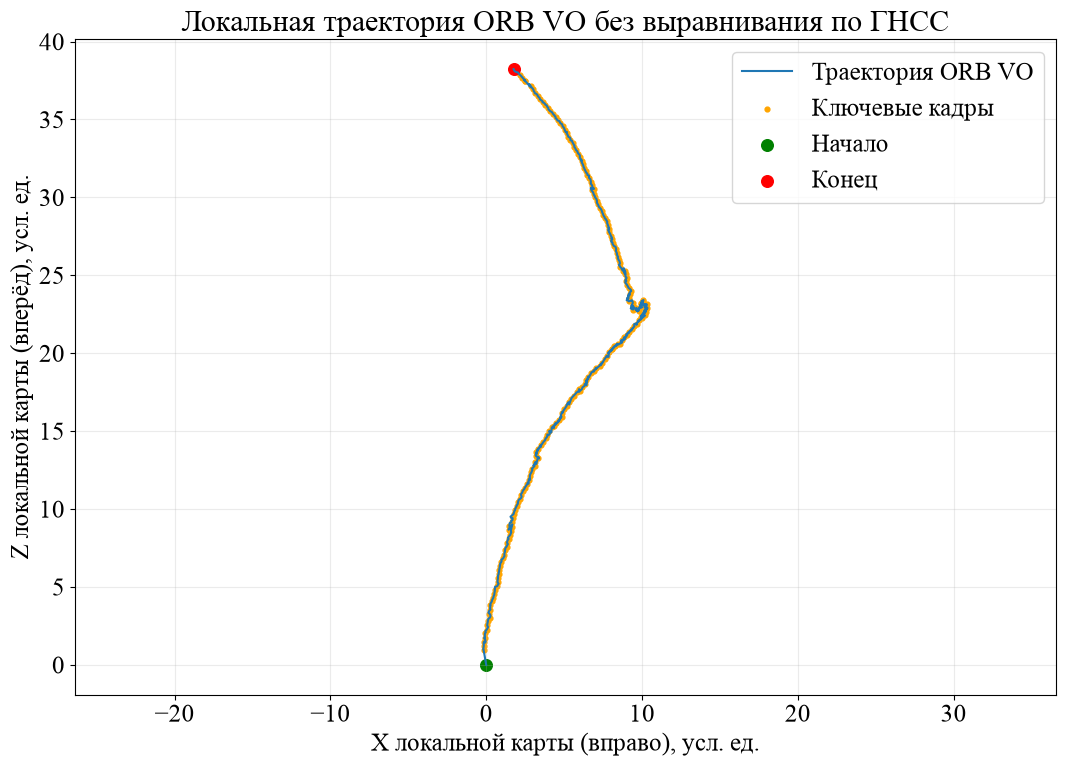

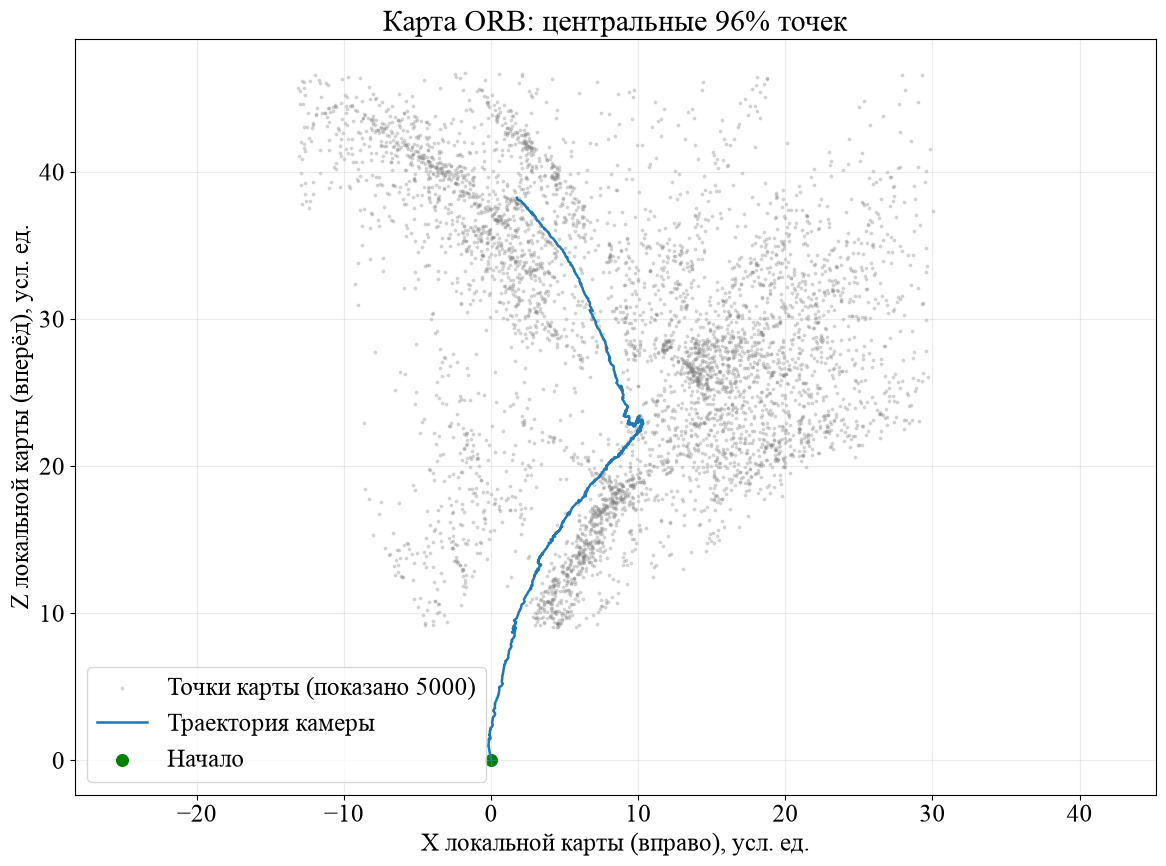

In [10]:
def rotation_to_quaternion(R):
    # Перевод матрицы поворота в кватернион с устойчивым выбором ветки по следу/диагонали.
    trace = np.trace(R)
    if trace > 0:
        s = np.sqrt(trace + 1.0) * 2
        qw = 0.25 * s
        qx, qy, qz = (R[2, 1] - R[1, 2]) / s, (R[0, 2] - R[2, 0]) / s, (R[1, 0] - R[0, 1]) / s
    else:
        index = int(np.argmax(np.diag(R)))
        if index == 0:
            s = np.sqrt(1.0 + R[0, 0] - R[1, 1] - R[2, 2]) * 2
            qw, qx = (R[2, 1] - R[1, 2]) / s, 0.25 * s
            qy, qz = (R[0, 1] + R[1, 0]) / s, (R[0, 2] + R[2, 0]) / s
        elif index == 1:
            s = np.sqrt(1.0 + R[1, 1] - R[0, 0] - R[2, 2]) * 2
            qw, qy = (R[0, 2] - R[2, 0]) / s, 0.25 * s
            qx, qz = (R[0, 1] + R[1, 0]) / s, (R[1, 2] + R[2, 1]) / s
        else:
            s = np.sqrt(1.0 + R[2, 2] - R[0, 0] - R[1, 1]) * 2
            qw, qz = (R[1, 0] - R[0, 1]) / s, 0.25 * s
            qx, qy = (R[0, 2] + R[2, 0]) / s, (R[1, 2] + R[2, 1]) / s
    quaternion = np.array([qx, qy, qz, qw])
    return quaternion / np.linalg.norm(quaternion)

def pose_to_tum(index, pose):
    # TUM хранит camera→world: центр камеры и ориентацию, обратную world→camera.
    R_wc = pose[:3, :3].T
    center = -R_wc @ pose[:3, 3]
    quaternion = rotation_to_quaternion(R_wc)
    return [timestamps[index], *center, *quaternion]

with (RESULTS_DIR / 'orb_tum.txt').open('w', encoding='utf-8') as stream:
    for index in sorted(successful_poses):
        stream.write(' '.join(f'{value:.9f}' for value in pose_to_tum(index, successful_poses[index])) + '\n')
with (RESULTS_DIR / 'orb_metrics.csv').open('w', newline='', encoding='utf-8') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(diagnostics[0]))
    writer.writeheader()
    writer.writerows(diagnostics)

centers = np.array([-pose[:3, :3].T @ pose[:3, 3] for _, pose in sorted(successful_poses.items())])
keyframe_centers = np.array([-successful_poses[i][:3, :3].T @ successful_poses[i][:3, 3]
                             for i in keyframe_indices if i in successful_poses])
figure, axis = plt.subplots(figsize=(11, 8))
axis.plot(centers[:, 0], centers[:, 2], linewidth=1.5, label='Траектория ORB VO')
axis.scatter(keyframe_centers[:, 0], keyframe_centers[:, 2], s=12, color='orange', label='Ключевые кадры')
axis.scatter(*centers[0, [0, 2]], color='green', s=70, label='Начало')
axis.scatter(*centers[-1, [0, 2]], color='red', s=70, label='Конец')
axis.set(xlabel='X локальной карты (вправо), усл. ед.',
         ylabel='Z локальной карты (вперёд), усл. ед.',
         title='Локальная траектория ORB VO без выравнивания по ГНСС')
axis.axis('equal')
axis.grid(alpha=0.25)
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS_DIR / 'orb_trajectory_local.png', dpi=200, bbox_inches='tight')

# Сохраняем саму карту, а не только траекторию: XYZ, параллакс, репроекцию и число наблюдений.
with (RESULTS_DIR / 'orb_map.csv').open('w', newline='', encoding='utf-8') as stream:
    writer = csv.writer(stream)
    writer.writerow(['x', 'y', 'z', 'parallax_deg', 'reprojection_px', 'observations', 'last_seen_frame'])
    for xyz, parallax, reprojection, observations, last_seen in zip(
            map_points, map_parallax_deg, map_reprojection_px, map_observations, map_last_seen):
        writer.writerow([*xyz, parallax, reprojection, observations, last_seen])

map_xyz = np.asarray(map_points)
if len(map_xyz):
    # На рисунке оставляем центральные 96% по X/Z только для читаемого масштаба.
    lower, upper = np.percentile(map_xyz[:, [0, 2]], [2, 98], axis=0)
    central = ((map_xyz[:, 0] >= lower[0]) & (map_xyz[:, 0] <= upper[0]) &
               (map_xyz[:, 2] >= lower[1]) & (map_xyz[:, 2] <= upper[1]))
    visible_map = map_xyz[central]
    if len(visible_map) > 5000:
        draw_indices = np.linspace(0, len(visible_map) - 1, 5000).astype(int)
        visible_map = visible_map[draw_indices]
    figure, axis = plt.subplots(figsize=(12, 9))
    axis.scatter(visible_map[:, 0], visible_map[:, 2], s=3, color='tab:gray', alpha=0.25,
                 label=f'Точки карты (показано {len(visible_map)})')
    axis.plot(centers[:, 0], centers[:, 2], color='tab:blue', linewidth=1.8, label='Траектория камеры')
    axis.scatter(*centers[0, [0, 2]], color='green', s=70, label='Начало')
    axis.set(xlabel='X локальной карты (вправо), усл. ед.',
             ylabel='Z локальной карты (вперёд), усл. ед.',
             title='Карта ORB: центральные 96% точек')
    axis.axis('equal')
    axis.grid(alpha=0.25)
    axis.legend()
    figure.tight_layout()
    figure.savefig(RESULTS_DIR / 'orb_map.png', dpi=200, bbox_inches='tight')

print(f'Сохранено {len(successful_poses)} TUM-поз, {len(diagnostics)} строк диагностики и {len(map_points)} точек карты')


## 7. Проверка и выводы

Маска должна исключать неподвижные элементы, RANSAC и PnP — сохранять достаточно inliers, репроекция — оставаться малой, а трекинг — покрывать последовательность. Малое покрытие важнее обманчиво гладкой короткой траектории. Сохранённые TUM/CSV/JSON используются далее для повторного сравнения с прямым методом и ГНСС.

In [ ]:
tracked_rows = [row for row in diagnostics if row['status'] == 'tracked']
runtimes = np.array([row['runtime_s'] for row in tracked_rows])
pnp_values = np.array([row['pnp_inliers'] for row in tracked_rows])
reprojection_values = np.array([row['median_reprojection_px'] for row in tracked_rows])
summary = {
    'algorithm': 'educational_orb_vo_not_full_orb_slam2',
    'frames': len(image_paths), 'valid_poses': len(successful_poses),
    'completeness': len(successful_poses) / len(image_paths),
    'lost_frames': lost_frames, 'keyframes': len(keyframe_indices), 'map_points': len(map_points),
    'mask_excluded_percent': float(excluded_percent),
    'initialization_essential_inliers': essential_inliers,
    'initialization_matches': len(initialization_matches),
    'min_pnp_inliers_required': MIN_PNP_INLIERS,
    'guided_projection_tracking': True,
    'median_map_parallax_deg': float(np.median(map_parallax_deg)) if map_parallax_deg else None,
    'median_map_observations': float(np.median(map_observations)) if map_observations else None,
    'relocalized_frames': sum(row['relocalized'] for row in diagnostics),
    'median_pnp_inliers': float(np.median(pnp_values)) if len(pnp_values) else None,
    'median_reprojection_px': float(np.nanmedian(reprojection_values)) if len(reprojection_values) else None,
    'runtime_mean_s': float(runtimes.mean()) if len(runtimes) else None,
    'runtime_p95_s': float(np.percentile(runtimes, 95)) if len(runtimes) else None,
    'mono_scale_constant': MONO_SCALE_CONSTANT,
    'scale_constraint': 'Fixed frame baseline from initialization; assumes nearly constant speed; no GNSS input',
    'keyframe_essential_correction': True,
    'calibration_warning': 'Temporary fx/fy estimate; not a checkerboard calibration',
}
(RESULTS_DIR / 'orb_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(summary, ensure_ascii=False, indent=2))
if summary['completeness'] < 0.95:
    print('ВЫВОД: есть потерянные кадры; ATE относится только к сохранённым позам.')
if summary['median_reprojection_px'] is not None and summary['median_reprojection_px'] < 1.0:
    print('ВЫВОД: медианная репроекция <1 px, но временная калибровка и дрейф масштаба остаются ограничениями.')